# 04 - Évaluation et comparaison des modèles (section 2.3)

In [1]:
import sys
from pathlib import Path

# Remonte jusqu'à la racine du projet (le dossier qui contient src/), quel que soit le dossier de lancement
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

import json
import joblib

from src.load_data import load_wine_data, make_binary_target, split_data
from src.preprocess import clean_data
from src.models import MODELS_DIR, load_selected_features
from src.evaluate import (
    compare_models, evaluate, plot_confusion_matrix, plot_learning_curve,
    plot_roc_curves, plot_validation_curve, train_vs_cv_scores,
)

## 1. Données et modèles disponibles

In [2]:
df = make_binary_target(clean_data(load_wine_data()))
X_train, X_test, y_train, y_test = split_data(df)
features = load_selected_features()

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Variables retenues (notebook 02) :", features)

models = {
    p.stem: joblib.load(p)
    for p in sorted(MODELS_DIR.glob("*.joblib"))
    if p.stem != "preprocessor"
}
print("Modèles chargés :", list(models))

Lignes supprimées (doublons ou NA) : 1177
Train : (4256, 12) | Test : (1064, 12)
Variables retenues (notebook 02) : ['volatile acidity', 'residual sugar', 'density', 'alcohol']
Modèles chargés : ['arbre_decision', 'knn', 'naive_bayes', 'regression_logistique', 'svm']


## 2. Métriques sur le jeu de test

In [3]:
results = {name: evaluate(model, X_test, y_test) for name, model in models.items()}
comparison = compare_models(results)
comparison.round(3)

,accuracy,precision,recall,f1,roc_auc
svm,0.728,0.399,0.851,0.543,0.842
knn,0.793,0.467,0.634,0.538,0.845
regression_logistique,0.712,0.373,0.752,0.498,0.804
arbre_decision,0.709,0.366,0.733,0.488,0.784
naive_bayes,0.693,0.352,0.738,0.477,0.772


## 3. Matrices de confusion

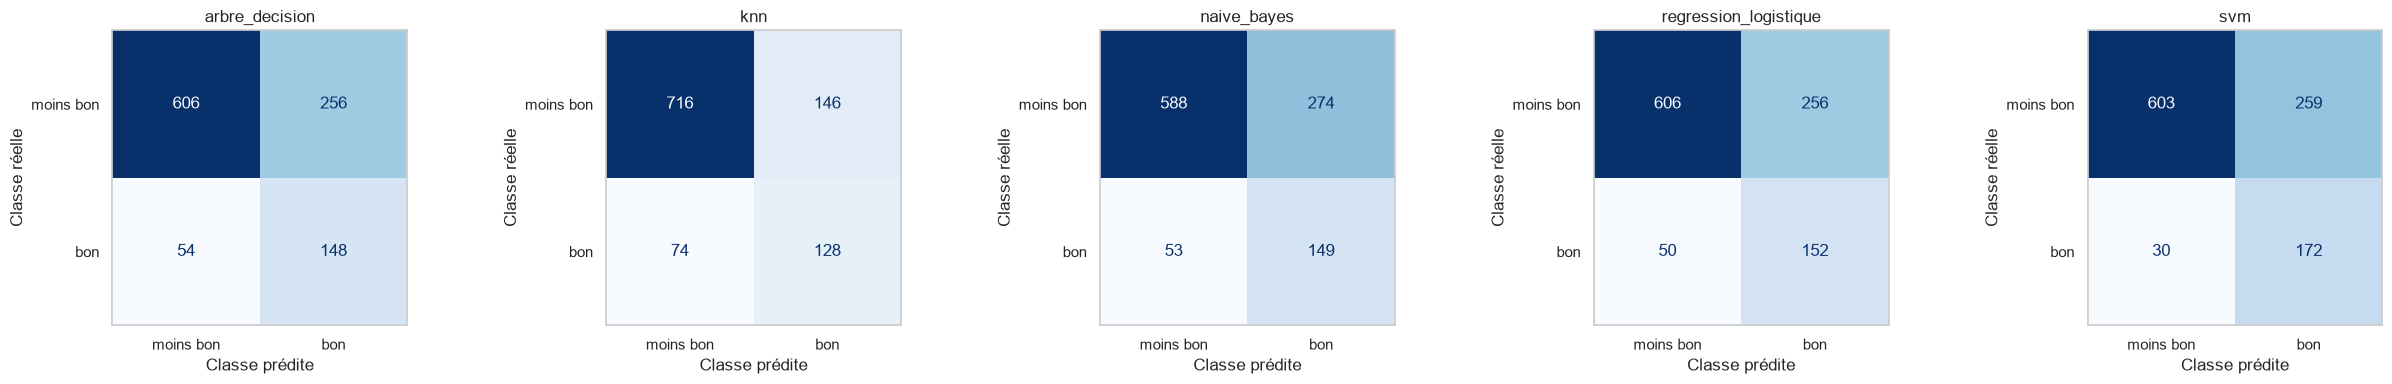

In [4]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4), squeeze=False)
for ax, (name, r) in zip(axes[0], results.items()):
    plot_confusion_matrix(r, title=name, ax=ax)
plt.tight_layout()
plt.show()

## 4. Courbes ROC et AUC

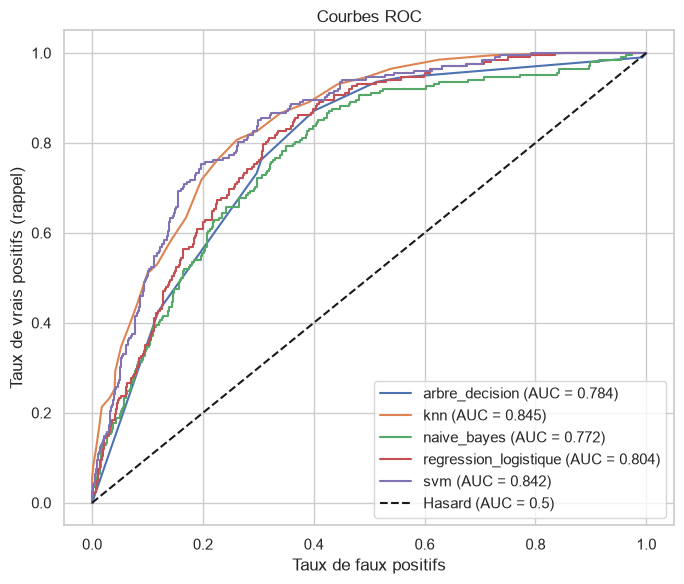

In [5]:
plt.figure(figsize=(7, 6))
plot_roc_curves(results)
plt.tight_layout()
plt.show()

## 5. Analyse biais / variance
### 5.1 Scores train vs validation croisée (5 plis, F1)

In [6]:
bias_variance = pd.DataFrame(
    {name: train_vs_cv_scores(model, X_train, y_train) for name, model in models.items()}
).T.sort_values("validation", ascending=False)
bias_variance.round(3)

,train,validation,validation_std,ecart
svm,0.549,0.541,0.010,0.008
knn,0.559,0.540,0.027,0.019
regression_logistique,0.526,0.528,0.012,-0.002
arbre_decision,0.528,0.516,0.017,0.012
naive_bayes,0.497,0.498,0.018,-0.001


### 5.2 Courbes d'apprentissage

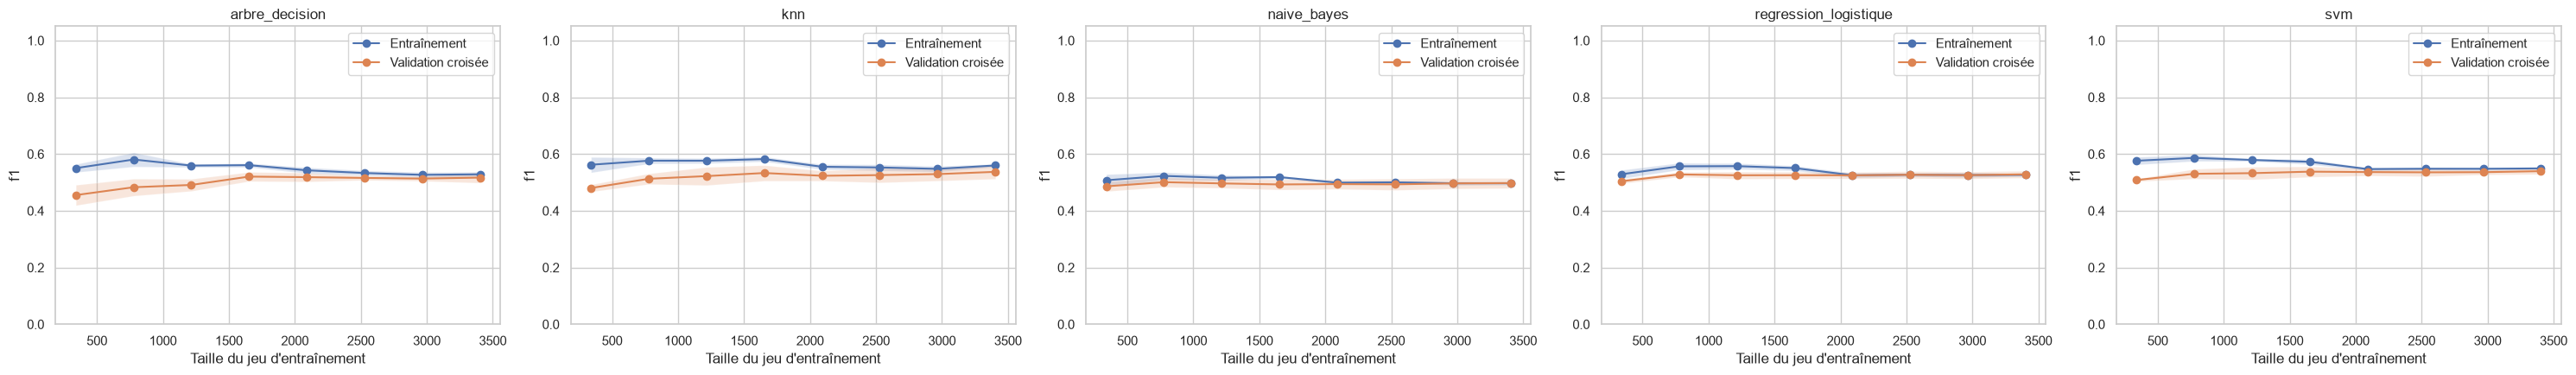

In [7]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 4.5), squeeze=False)
for ax, (name, model) in zip(axes[0], models.items()):
    plot_learning_curve(model, X_train, y_train, title=name, ax=ax)
    ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### 5.3 Courbes de validation : effet de la complexité

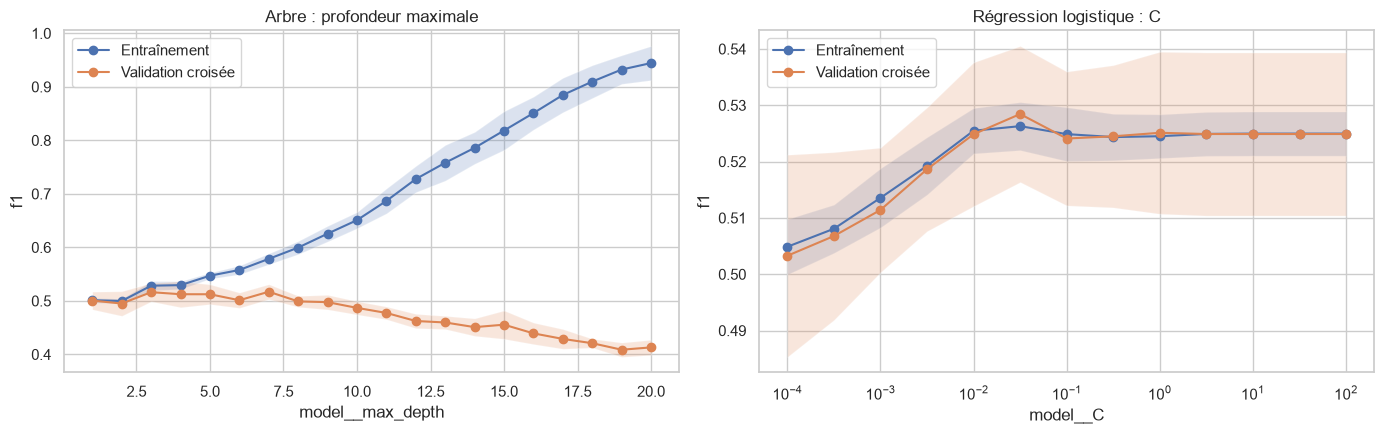

In [8]:
from src.models import decision_tree, logistic_regression

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_validation_curve(decision_tree(features), X_train, y_train, "model__max_depth", list(range(1, 21)),
                      title="Arbre : profondeur maximale", ax=axes[0])
plot_validation_curve(logistic_regression(features), X_train, y_train, "model__C", np.logspace(-4, 2, 13),
                      title="Régression logistique : C", ax=axes[1])
axes[1].set_xscale("log")
plt.tight_layout()
plt.show()

### 5.4 Les 4 variables retenues limitent-elles les modèles ?

In [9]:
from sklearn.base import clone

rows = {}
for name in ["regression_logistique", "arbre_decision"]:
    for label, cols in [("4 variables", features), ("12 variables", None)]:
        model = clone(models[name]).set_params(prep__select__columns=cols)
        rows[(name, label)] = train_vs_cv_scores(model, X_train, y_train)
pd.DataFrame(rows).T.round(3)

train  validation  validation_std  ecart
regression_logistique 4 variables   0.526       0.528           0.012 -0.002
                      12 variables  0.540       0.539           0.025  0.001
arbre_decision        4 variables   0.528       0.516           0.017  0.012
                      12 variables  0.521       0.502           0.019  0.018

## 6. Choix du modèle final

In [10]:
final_name = bias_variance["validation"].idxmax()

with open(MODELS_DIR / "final_model.json", "w", encoding="utf-8") as f:
    json.dump({"name": final_name, "features": features}, f, indent=2, ensure_ascii=False)

print("Modèle final :", final_name)
pd.concat([bias_variance.loc[final_name].add_prefix("cv_"), comparison.loc[final_name].add_prefix("test_")]).round(3)

Modèle final : svm


cv_train             0.549
cv_validation        0.541
cv_validation_std    0.010
cv_ecart             0.008
test_accuracy        0.728
test_precision       0.399
test_recall          0.851
test_f1              0.543
test_roc_auc         0.842
Name: svm, dtype: float64